<a href="https://colab.research.google.com/github/danirdz-afk/Actividades-equipo-4/blob/main/AF8_RNC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



Actividad Fundamental 8: Redes Neuronales Convolucionales

Docente: Ing. Daniel Isaias López Páez

Hora de clase: Jueves N1-N3

Integrantes:

Pedro Daniel Carbajal Cruz - 2222798

Daniel Rodríguez Arellano - 2041848

José Adrián Hernández Hernández - 1891823

Edgar Ivan Martinez Ramirez - 2120721

Luis Angel Rodriguez Gutierrez - 2059357


1.- Cargar Librerias.

In [1]:

import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np

print("Librerías cargadas para el modelo convolucional.")

Librerías cargadas para el modelo convolucional.


2.- Cargar Datos.

In [2]:

# Carga de datos de entrenamiento y prueba
(train_data, train_labels), (test_data, test_labels) = datasets.mnist.load_data()

print(f"Set de entrenamiento: {train_data.shape}")
print(f"Set de prueba: {test_data.shape}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Set de entrenamiento: (60000, 28, 28)
Set de prueba: (10000, 28, 28)


3.- Preprocesamiento De Datos.

In [3]:

# Normalización de píxeles
train_data = train_data.astype("float32") / 255
test_data = test_data.astype("float32") / 255

# Ajuste de dimensiones (Agregar canal de color: 28x28x1)
train_data = train_data.reshape((60000, 28, 28, 1))
test_data = test_data.reshape((10000, 28, 28, 1))

print("Preprocesamiento finalizado con éxito.")

Preprocesamiento finalizado con éxito.


4.- Seleccion Y Entrenamiento Del Modelo.

In [4]:
# Definición de la estructura del modelo CNN
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax') # Capa de salida obligatoria
])

# Configuración: Optimizador Adam, Función de pérdida y Métrica de Exactitud
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Entrenamiento del modelo
print("Iniciando entrenamiento...")
model.fit(train_data, train_labels, epochs=5)

Iniciando entrenamiento...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 56s 29ms/step - accuracy: 0.9617 - loss: 0.1266
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 82s 29ms/step - accuracy: 0.9868 - loss: 0.0423
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 82s 29ms/step - accuracy: 0.9919 - loss: 0.0258
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 82s 29ms/step - accuracy: 0.9944 - loss: 0.0183
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 82s 29ms/step - accuracy: 0.9955 - loss: 0.0141


5.- Prueba Del Modelo Y Predicciones

313/313 - 3s - 8ms/step - accuracy: 0.9875 - loss: 0.0406

Exactitud de predicción del modelo: 0.9875
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step

--- Resultados de 5 Predicciones ---
Muestra 1: Predicción = 7 | Valor Real = 7
Muestra 2: Predicción = 2 | Valor Real = 2
Muestra 3: Predicción = 1 | Valor Real = 1
Muestra 4: Predicción = 0 | Valor Real = 0
Muestra 5: Predicción = 4 | Valor Real = 4


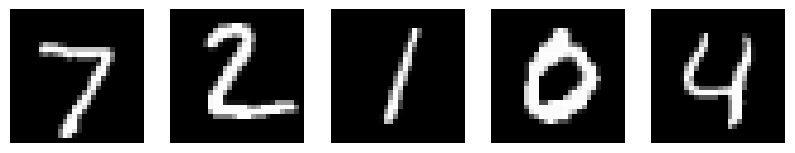

In [5]:

# Evaluación con el conjunto de prueba
test_loss, test_acc = model.evaluate(test_data, test_labels, verbose=2)
print(f'\nExactitud de predicción del modelo: {test_acc:.4f}')

# Realización de 5 predicciones
predictions = model.predict(test_data)

print("\n--- Resultados de 5 Predicciones ---")
for i in range(5):
    prediccion = np.argmax(predictions[i])
    real = test_labels[i]
    print(f"Muestra {i+1}: Predicción = {prediccion} | Valor Real = {real}")

# Visualización de las imágenes probadas
plt.figure(figsize=(10, 2))
for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(test_data[i].reshape(28, 28), cmap='gray')
    plt.axis('off')
plt.show()